# 01 Data Prep and EDA

**Owner:** Cesar Rivera  |  **Status:** Done

**Goal:** turn the Kaggle detection dataset into a classification dataset, create the one frozen train/val/test split everyone uses, and plot how much the data varies.

**Rubric items this feeds:** Feature Extraction (plots showing variation in the dataset), Generalizability (data split).

> **Do this first:** after section 4, push ~20 starter crops per class so notebooks 02-04 can start prototyping before the full split exists.

## 1. Setup

In [ ]:
!git clone https://github.com/theyogurt/DATASCI281_ComputerVision---FINAL_PROJECT_ROAD_SIGN_CLASSIFIER.git
%cd DATASCI281_ComputerVision---FINAL_PROJECT_ROAD_SIGN_CLASSIFIER/notebooks

In [4]:
import kagglehub, shutil

path = kagglehub.dataset_download("andrewmvd/road-sign-detection")
DATA_RAW.mkdir(parents=True, exist_ok=True)
shutil.copytree(path, DATA_RAW, dirs_exist_ok=True)

100%|██████████| 218M/218M [00:02<00:00, 91.5MB/s]

Extracting files...


PosixPath('/content/DATASCI281_ComputerVision---FINAL_PROJECT_ROAD_SIGN_CLASSIFIER/data/raw')

In [5]:
import sys
sys.path.append("..")  # run from notebooks/, so ".." is the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (
    SEED, IMAGE_SIZE, CLASSES, DATA_RAW, DATA_PROCESSED, DATA_SPLITS,
    load_split, load_image, load_split_images, save_features, load_features,
    timed, evaluate, plot_confusion_matrix, record_result,
)

np.random.seed(SEED)

## 2. Get the raw data

1. Download from [Kaggle: Road Sign Detection](https://www.kaggle.com/datasets/andrewmvd/road-sign-detection).
2. Unzip into `data/raw/` so you have `data/raw/images/*.png` and `data/raw/annotations/*.xml` (adjust the paths below if the folder names differ).

In [8]:
images_dir = DATA_RAW / "images"
ann_dir = DATA_RAW / "annotations"
print(len(list(images_dir.glob("*.png"))), "images")
print(len(list(ann_dir.glob("*.xml"))), "annotation files")

877 images
877 annotation files


## 3. Parse the annotations

Each XML file is PASCAL VOC format: one `<object>` per sign with a `<name>` (class) and a `<bndbox>` (`xmin`, `ymin`, `xmax`, `ymax`).

TODO: build a DataFrame with one row per labeled sign: `image`, `label`, `xmin`, `ymin`, `xmax`, `ymax`. Expected total: 1,244 rows (783 speedlimit, 200 crosswalk, 170 trafficlight, 91 stop).

In [10]:
import xml.etree.ElementTree as ET

def parse_annotations(ann_dir):
    rows = []
    for xml_file in sorted(ann_dir.glob("*.xml")):
        root = ET.parse(xml_file).getroot()
        image = root.findtext("filename")
        for obj in root.findall("object"):
            box = obj.find("bndbox")
            rows.append({
                "image": image,
                "label": obj.findtext("name"),
                **{k: int(float(box.findtext(k))) for k in ["xmin", "ymin", "xmax", "ymax"]},
            })
    return pd.DataFrame(rows)

boxes = parse_annotations(ann_dir)
boxes.head()

,image,label,xmin,ymin,xmax,ymax
0,road0.png,trafficlight,98,62,208,232
1,road1.png,trafficlight,154,63,258,281
2,road10.png,trafficlight,106,3,244,263
3,road100.png,speedlimit,35,5,363,326
4,road101.png,speedlimit,195,7,392,194


In [11]:
print(len(boxes), "rows")
boxes["label"].value_counts()

1244 rows


,count
label,
speedlimit,783
crosswalk,200
trafficlight,170
stop,91


## 4. Crop each sign into its own image

Save each crop to `data/processed/<label>/<image>_<k>.png`.

Decisions to make and write down in the notes section:
- minimum crop size (some boxes are under 10 px; keep or drop?)
- whether to pad the box slightly

In [13]:
from pathlib import Path
from PIL import Image

ROOT = DATA_RAW.parents[1]

def crop_signs(boxes, images_dir, out_dir, min_size=16, pad=0.1):
    records = []
    for image, group in boxes.groupby("image"):
        img = Image.open(images_dir / image).convert("RGB")
        W, H = img.size
        for k, r in enumerate(group.itertuples()):
            w, h = r.xmax - r.xmin, r.ymax - r.ymin
            if min(w, h) < min_size:
                continue
            px, py = int(w * pad), int(h * pad)
            box = (max(0, r.xmin - px), max(0, r.ymin - py),
                   min(W, r.xmax + px), min(H, r.ymax + py))
            out_path = out_dir / r.label / f"{Path(image).stem}_{k}.png"
            out_path.parent.mkdir(parents=True, exist_ok=True)
            img.crop(box).save(out_path)
            records.append({
                "path": str(out_path.relative_to(ROOT)),
                "label": r.label,
                "source_image": image,
                "width": w, "height": h,
            })
    return pd.DataFrame(records)

crops = crop_signs(boxes, images_dir, DATA_PROCESSED)
print(len(crops), "crops kept of", len(boxes))
crops["label"].value_counts()

1106 crops kept of 1244


,count
label,
speedlimit,729
crosswalk,160
trafficlight,133
stop,84


## 5. Frozen train/val/test split

- Stratify by class and use `SEED` from `utils.py`.
- **Keep crops from the same source photo in the same split** (a photo can contain several signs), otherwise near-duplicate backgrounds leak across splits. `sklearn`'s `StratifiedGroupKFold` or `GroupShuffleSplit` can do this.
- Write `data/splits/train.csv`, `val.csv`, `test.csv` with columns `path` (relative to the repo root), `label`, and `source_image`.
- Everyone loads these files with `load_split(...)`. Nobody re-splits.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

def take_fold(df, n_splits):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    rest_idx, hold_idx = next(sgkf.split(df, df["label"], groups=df["source_image"]))
    return df.iloc[rest_idx], df.iloc[hold_idx]

rest, test = take_fold(crops, 7)   # 1/7 for test
train, val = take_fold(rest, 6)    # 1/6 of the rest for val

DATA_SPLITS.mkdir(parents=True, exist_ok=True)
cols = ["path", "label", "source_image"]
for name, df in [("train", train), ("val", val), ("test", test)]:
    df[cols].to_csv(DATA_SPLITS / f"{name}.csv", index=False)

In [15]:
splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
print(pd.crosstab(splits["label"], splits["split"]))

# no photo should appear in more than one split
assert splits.groupby("source_image")["split"].nunique().max() == 1

split         test  train  val
label                         
crosswalk       20    113   27
speedlimit     110    516  103
stop            14     56   14
trafficlight    12     96   25


## 6. Dataset variation plots

TODO: make these plots (each needs a title, axis labels, and one sentence of interpretation):
- [ ] class counts (bar chart) per split
- [ ] crop width/height distributions, and aspect ratio by class
- [ ] mean color (HSV or RGB) by class
- [ ] example grid: 6-8 crops per class showing lighting / angle / size variation

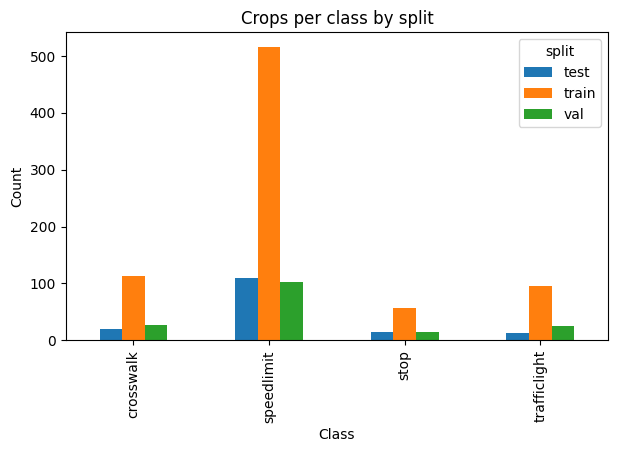

In [16]:
pd.crosstab(splits["label"], splits["split"]).plot.bar(figsize=(7, 4))
plt.title("Crops per class by split"); plt.xlabel("Class"); plt.ylabel("Count")
plt.show()

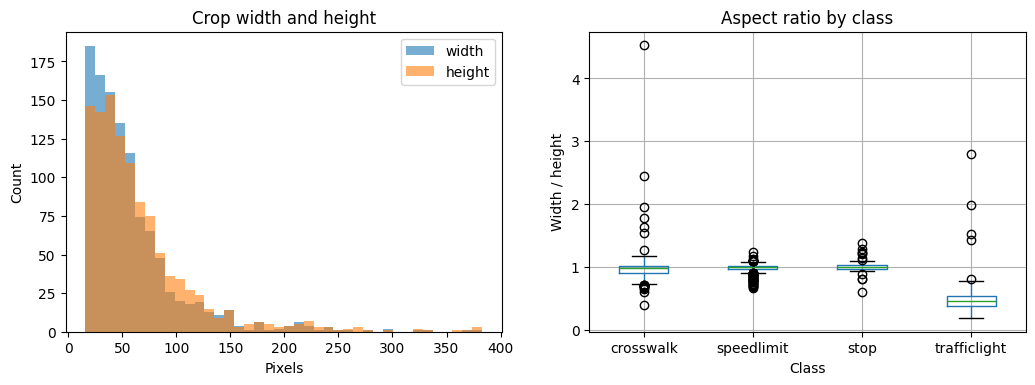

In [17]:
crops["aspect"] = crops["width"] / crops["height"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
crops[["width", "height"]].plot.hist(bins=40, alpha=0.6, ax=axes[0])
axes[0].set(title="Crop width and height", xlabel="Pixels", ylabel="Count")
crops.boxplot(column="aspect", by="label", ax=axes[1])
axes[1].set(title="Aspect ratio by class", xlabel="Class", ylabel="Width / height")
plt.suptitle(""); plt.show()

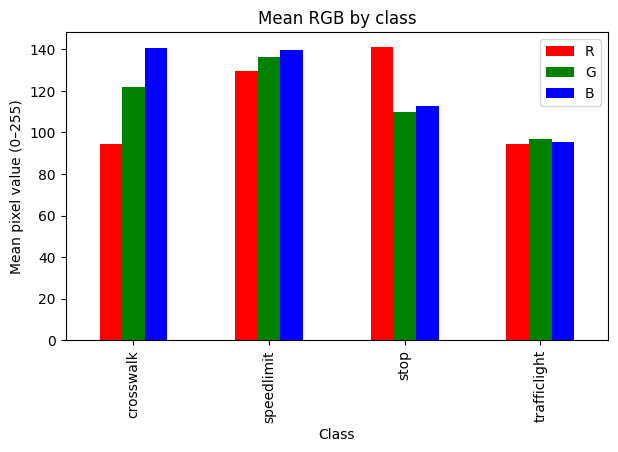

In [18]:
crops[["R", "G", "B"]] = [np.asarray(Image.open(ROOT / p)).reshape(-1, 3).mean(0) for p in crops["path"]]
crops.groupby("label")[["R", "G", "B"]].mean().plot.bar(color=["red", "green", "blue"], figsize=(7, 4))
plt.title("Mean RGB by class"); plt.xlabel("Class"); plt.ylabel("Mean pixel value (0–255)")
plt.show()

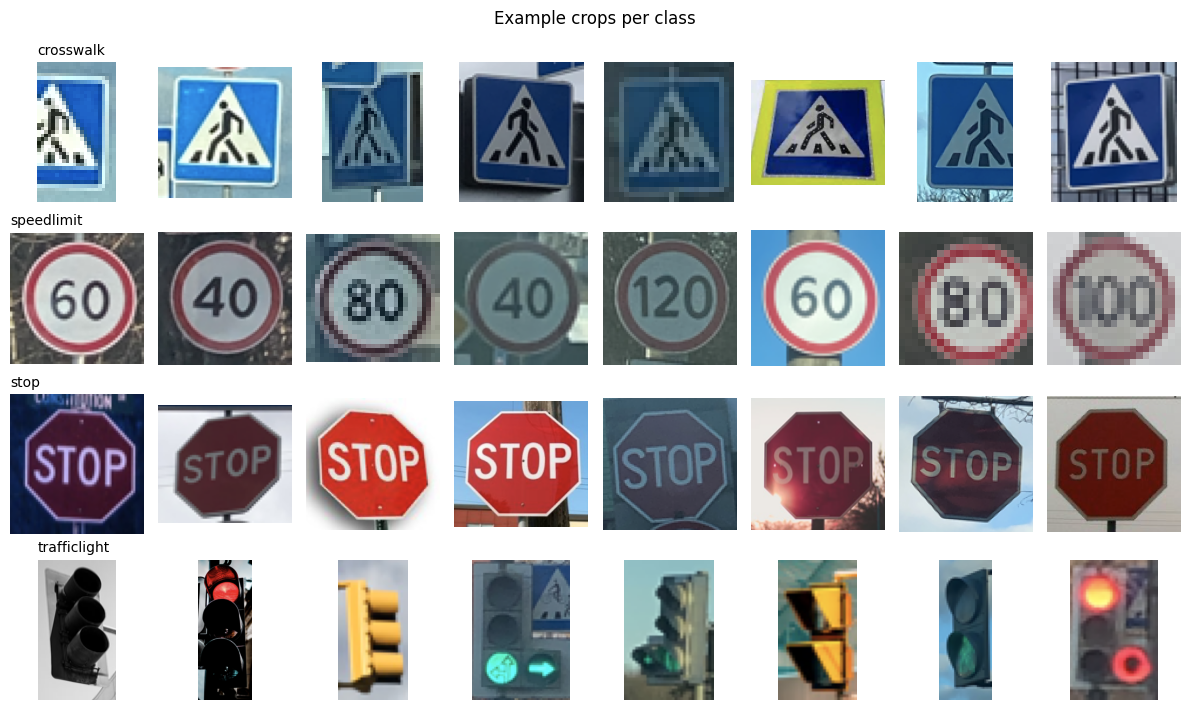

In [19]:
labels = sorted(crops["label"].unique())
fig, axes = plt.subplots(len(labels), 8, figsize=(12, 1.8 * len(labels)))
for i, label in enumerate(labels):
    sample = crops[crops["label"] == label].sample(8, random_state=SEED)
    for j, p in enumerate(sample["path"]):
        axes[i, j].imshow(Image.open(ROOT / p)); axes[i, j].axis("off")
    axes[i, 0].set_title(label, loc="left", fontsize=10)
plt.suptitle("Example crops per class"); plt.tight_layout(); plt.show()

## 7. Notes for the team

TODO: record the decisions others need to know (final crop counts per class, minimum crop size, split ratios, anything surprising in the data).

- Crops kept: 1,106 of 1,244 (speedlimit 729, crosswalk 160, trafficlight 133, stop 84)
- Minimum crop size: 16 px; smaller boxes dropped. Trafficlight and crosswalk lost ~20% each, speedlimit and stop ~7–8%.
- Padding: 10% on each side, clipped to the image
- Split: StratifiedGroupKFold grouped by source photo, SEED from utils.py
  - train 781 / val 169 / test 156 (~71/15/14)
  - no source photo appears in more than one split
- Surprises:
  - strong class imbalance (speedlimit ~66%), so report per-class metrics / macro F1, not just accuracy
  - test set has only 12 trafficlight and 14 stop crops
  - traffic lights are tall (aspect ~0.5); the other classes are roughly square
  - most crops are under 60 px, so they get upscaled

Backup: DATASCI281_backup/data_v1.zip on Cesar’s Drive.